<a href="https://colab.research.google.com/github/abdullahkras-dot/Pytorch-workflow/blob/pytorch-fundementals/00_pytorch_fundementals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#importing our stuff
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms.functional as F
print(torch.__version__)

2.14.1+cpu


In [ ]:
#tensor stuff


In [ ]:
#scalars
scalar = torch.tensor(-7)
vector = torch.tensor([1,2,3])
matrix = torch.tensor([[1,2,3],[4,5,6],[7,8,9],[3,5,6]])
tensor = torch.tensor([[[1,2,3],[4,5,6],[7,8,9],[3,5,6]]])

print(scalar) #python object
print(scalar.abs()) #gives abs value
print(scalar.ndim) #gives tensor dimension
print(scalar.item()) #gives python int
print(matrix.shape)
print(matrix.size())
print(tensor.shape)
print(tensor.size())

tensor(-7)
tensor(7)
0
-7
torch.Size([4, 3])
torch.Size([4, 3])
torch.Size([1, 4, 3])
torch.Size([1, 4, 3])


In [ ]:
gen = torch.Generator()
gen.manual_seed(42)

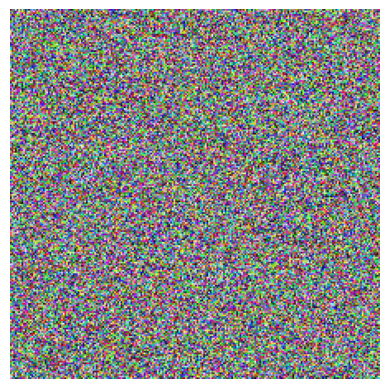

In [ ]:
img = torch.rand([3,224,224])

img_np = img.detach().cpu().permute(1, 2, 0).numpy()

plt.imshow(img_np)
plt.axis("off")
plt.show()



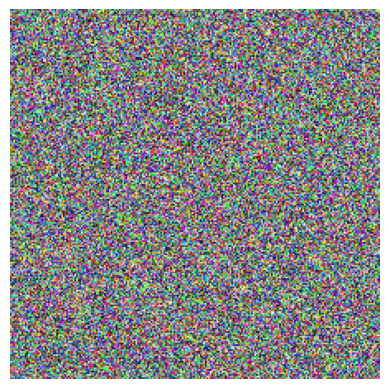

In [ ]:
img2 = torch.randint(high = 255,low = 0,size = [3,224,224])
img_np = img2.detach().cpu().permute(1, 2, 0).numpy()

plt.imshow(img_np)
plt.axis("off")
plt.show()



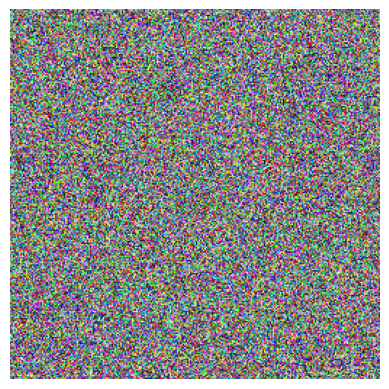

In [ ]:
plt.imshow(F.to_pil_image(torch.rand(3, 255, 255)))
plt.axis("off")
plt.show()

In [ ]:
(torch.rand(1,1)*torch.randint(high = 1, low = 0,size = [1,1])).dtype

torch.float32

In [ ]:
torch.arange(0,10,step = 4)

tensor([0, 4, 8])

In [ ]:
torch.zeros(size = (3,4))

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])

In [ ]:
torch.ones(1,4)


tensor([[1., 1., 1., 1.]])

In [ ]:
torch.zeros_like(input=(torch.tensor([1,3])))

tensor([0, 0])

**3 annoying problems**
tensor is not right
datatype
shape
device

In [ ]:
float_32_tensor = torch.tensor([1,3,4],
             dtype = None, # data type
             device = None, # device (cpu, cuda)
             requires_grad = False # track gradient
             )

In [ ]:
float_16_tensor = float_32_tensor.type(torch.float16)



In [ ]:
float_16_tensor*float_32_tensor

tensor([ 1.,  9., 16.], dtype=torch.float16)

float * int = int (for tensors)
float32 * float16 = float16

In [ ]:
int_float32 = torch.randint(high = 1,low = 0,size = [4,3,1] )*float_32_tensor

In [ ]:
int_float32.dtype

torch.int64

Tensors can do element wise multiplication and also matrix multiplication

In [ ]:
torch.tensor([[1,3,4]])@torch.tensor([[1],[3],[3]])

tensor([[22]])

In [ ]:
torch.tensor([[1,2,3]])*torch.tensor([[1,2,3]
                                     ])

tensor([[1, 4, 9]])

In [ ]:
#we have transpose aswell (tensor).T
# can find min, max, mean, all sorts of data patterns
#argmin and max give index of our max and min

In [ ]:
test1 = torch.tensor([[1,2,3]])
torch.vstack([test1,test1])

tensor([[1, 2, 3],
        [1, 2, 3]])

In [ ]:
hstack = torch.hstack([test1,test1])


In [ ]:
#torch.reshape reshapes it if the dimentions match the amount of items
#in the tensor

In [ ]:
torch.stack([test1,test1],1)

tensor([[[1, 2, 3],
         [1, 2, 3]]])

In [ ]:
#stacks it on th desired channel


In [ ]:
#torch.squeeze "squeezes"(removes) all 1 dimentional channels

hstack,torch.squeeze(hstack)

(tensor([[1, 2, 3, 1, 2, 3]]), tensor([1, 2, 3, 1, 2, 3]))

In [ ]:
#torch.unsqueeze adds a dimention to whatever channel you chose

torch.unsqueeze(hstack,2)

tensor([[[1],
         [2],
         [3],
         [1],
         [2],
         [3]]])

In [ ]:
torch.unsqueeze(hstack,1)

tensor([[[1, 2, 3, 1, 2, 3]]])

In [ ]:
#permute changes around the dimentions of data
torch.permute(hstack,[1,0]),hstack

(tensor([[1],
         [2],
         [3],
         [1],
         [2],
         [3]]),
 tensor([[1, 2, 3, 1, 2, 3]]))

In [ ]:
#views give you an edited version of a tensor, but that edited tensor
#shares same memory as the original one, so if you edit one u edit both

In [ ]:
#list[start:stop:step]

t2 = torch.tensor([[1,2,3],
              [4,5,6],
              [7,8,9]])

In [ ]:
t2[:,2]

tensor([3, 6, 9])

In [ ]:
t3 = np.arange(1,8)
numpy_to_pytorch = torch.from_numpy(t3) # copies the np array
numpy_to_pytorch

tensor([1, 2, 3, 4, 5, 6, 7])

In [ ]:
pytorch_to_numpy = numpy_to_pytorch.numpy
pytorch_to_numpy

<function Tensor.numpy>

In [ ]:
gen = torch.Generator()

gen.manual_seed(42)
gen_state = gen.get_state()

gen2 = torch.Generator()
gen2.set_state(gen_state)

rand2 = torch.rand(3,3,generator = gen2)
rand1 = torch.rand(3,3,generator = gen)
rand1,rand2,rand1 == rand2


(tensor([[0.8823, 0.9150, 0.3829],
         [0.9593, 0.3904, 0.6009],
         [0.2566, 0.7936, 0.9408]]),
 tensor([[0.8823, 0.9150, 0.3829],
         [0.9593, 0.3904, 0.6009],
         [0.2566, 0.7936, 0.9408]]),
 tensor([[True, True, True],
         [True, True, True],
         [True, True, True]]))

In [ ]:
torch.manual_seed(42)
rand1 = torch.rand(3,3)
torch.manual_seed(42)
rand2 = torch.rand(3,3)
rand1,rand2,rand1 == rand2

(tensor([[0.8823, 0.9150, 0.3829],
         [0.9593, 0.3904, 0.6009],
         [0.2566, 0.7936, 0.9408]]),
 tensor([[0.8823, 0.9150, 0.3829],
         [0.9593, 0.3904, 0.6009],
         [0.2566, 0.7936, 0.9408]]),
 tensor([[True, True, True],
         [True, True, True],
         [True, True, True]]))

In [ ]:
g = torch.Generator().manual_seed(42)
state = g.get_state()

first_draw = torch.rand(3, generator=g)

# Restore state to repeat the exact same draw
g.set_state(state)
second_draw = torch.rand(3, generator=g)

first_draw, second_draw, first_draw == second_draw

(tensor([0.8823, 0.9150, 0.3829]),
 tensor([0.8823, 0.9150, 0.3829]),
 tensor([True, True, True]))

In [ ]:
!nvidia-gmi

/bin/bash: line 1: nvidia-gmi: command not found


In [ ]:
torch.cuda.is_available()

False

In [ ]:
torch.cuda.device_count()

0

In [ ]:
tensor.to

In [ ]:
shift+cmd+space for docstrigns